### Inference_Extract_Cube

In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import time
import ee
import geemap.foliumap as geemap  
import datetime
import rasterio

In [2]:
# Authenticate ee. You first need to set up a free Google Cloud account
ee.Authenticate()

True

In [3]:
# Initialise Earth Engine
ee.Initialize()  

## Center Point of Interest

In [4]:
# Biome A
# tambal, Tamil Nadu, India, Biome A, Tropical & Subtropical Dry Broadleaf Forest
lat = 11.933    # north - positive    
lon = 78.50     # east - positive

In [33]:
# Biome B
# serengeti, Tanzania, Biome B, Tropical & ST Grasslands, Savannas and Shrublands
lat = -2.317      # south
lon = 34.85       # east

In [57]:
# Biome C
# Ducos, Argentina, Biome C, Temperate Grasslands, Savannas and Shrublands
lat = -37.442    # south
lon = -62.429    # west

In [81]:
# Biome D
# Machuca, Cile, Biome D, Montane Grasslands and Shrublands
lat = -22.6      # south
lon = -68.067    # west

In [104]:
# Biome E
# Theisoa, Greece, Biome E, Mediterranean Forests, Woodlands and Scrub
lat = 37.5125     
lon = 21.9595

In [ ]:
# Biome F
# Siwa Oasis West, Egypt, Biome F, Deserts and Xeric Shrublands
lat = 29.217      
lon = 25.283

## Define Point

In [105]:
point = ee.Geometry.Point(lon,lat)    
point.getInfo()          # no projection just lat/lon EPSG 4326

{'type': 'Point', 'coordinates': [21.9595, 37.5125]}

In [106]:
point.projection().getInfo()

{'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [1, 0, 0, 0, 1, 0]}

### Create a box center of the point with bounds +/- 0.05 degrees lon and lat

In [107]:
box = ee.Geometry.BBox((lon-0.05), (lat-0.05), (lon+0.05), (lat+0.05))                     # box is ee.Geometry.BBox
box_fc =  ee.FeatureCollection(box).style(**{'color':'blue','fillColor': '#00000000'})     # convert to styled feature collection

## Plot image from Copernicus Collection

In [108]:
coll_sent = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')         # whole Sentinel-2 collection
    .filterDate('2024-01-01', '2024-12-31')                   # time period - end year of GLANCE sample    
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 50))      # cloud cover less than 50%
    .filterBounds(box)                                        # only images interesecting this feature
)

num_images = coll_sent.size().getInfo()     # no of images will be the same for 10m and 20m bands
print('num_images=',num_images)

num_images= 51


In [62]:
# bands of interest - 3 bands
coll_bands = coll_sent.select(['B2','B3','B4']) 

# first image sentinel
first_image_sent = coll_bands.first()

# image projection
proj_sent = coll_bands.first().select('B2').projection()

# median image
median_image_sent = coll_bands.median().reproject(proj_sent)

In [109]:
# bands of interest - 10 bands
coll_bands = coll_sent.select(['B2','B3','B4','B8','B5','B6','B7','B8A','B11','B12']) 

# first image sentinel
first_image_sent = coll_bands.first()

# image projection
proj_sent = coll_bands.first().select('B2').projection()

# median image
median_image_sent = coll_bands.median().reproject(proj_sent)

In [110]:
image_sent_crs = proj_sent.getInfo()['crs']
image_sent_crs

'EPSG:32634'

In [111]:
vis_sent = {'min':0.0, 'max':2500, 'bands': ['B4','B3','B2'],}           
vis_poly = {'color':'FF0000', 'width':2, 'fillColor':'00000000'}

In [112]:
Map = geemap.Map(height='500', width='60%')
Map.centerObject(box,zoom=13)
#Map.addLayer(coll_bands,vis_sent,'collection')
Map.addLayer(median_image_sent,vis_sent,'median_sent')

# Add centre point
Map.addLayer(point,{"color": "red"}, "point")

# Add polygon
Map.addLayer(box_fc, {}, "box_fc")

display(Map)

## Plot image from AlphaEarth collection which intersects point of interest

In [113]:
coll_alpha = (
    ee.ImageCollection('GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL')         # AlphaEarth collection
    .filterDate('2024-01-01', '2024-12-31')                            # time period     
    .filterBounds(box)                                                 # only images interesecting this feature
)

# first image alpha
first_image_alpha = coll_alpha.first()

# image projection
proj_alpha = coll_alpha.first().select('A00').projection()

# median image
median_image_alpha = coll_alpha.median().reproject(proj_alpha)  

num_images = coll_alpha.size().getInfo()     
print('num_images=',num_images)

num_images= 1


In [114]:
vis_alpha = {'min':-0.3, 'max':0.3, 'bands': ['A01','A02','A03']}    

In [ ]:
Map = geemap.Map(height='500', width='60%')
Map.centerObject(point,zoom=13)

Map.addLayer(median_image_sent,vis_sent,'sent')  
Map.addLayer(median_image_alpha,vis_alpha,'alpha') 

# Add centre point
Map.addLayer(point,{"color": "red"}, "point")    

# Add polygon
Map.addLayer(box_fc, {}, "box_fc")

Map

In [115]:
proj_alpha.getInfo()

{'type': 'Projection',
 'crs': 'EPSG:32634',
 'transform': [10, 0, 500000, 0, 10, 4096000]}

In [116]:
image_alpha_crs = proj_alpha.getInfo()['crs']
image_alpha_crs, image_sent_crs

('EPSG:32634', 'EPSG:32634')

### Get image dimensions in pixels

In [117]:
dimensions=first_image_sent.select('B2').getInfo()['bands'][0]['dimensions']
dimensions

[10980, 10980]

In [118]:
dimensions=first_image_alpha.select('A01').getInfo()['bands'][0]['dimensions']
dimensions

[16384, 16384]

### Transform point to same projection as image (UTM metres)

In [119]:
# Reproject (transform) point to Web Mercator
point_utm_sent = point.transform(image_sent_crs, 1)    # maxError = 1 meter. transform for points, reproject for images
point_utm_alpha = point.transform(image_alpha_crs, 1)  # maxError = 1 meter. transform for points, reproject for images

In [120]:
coordinates_sent=point_utm_sent.getInfo()['coordinates']
coordinates_alpha=point_utm_alpha.getInfo()['coordinates']
print(coordinates_sent, coordinates_alpha)

[584797.1708647074, 4152160.508077189] [584797.1708647074, 4152160.508077189]


In [23]:
### just for checking ###
# this takes a utm point and converts back to to lon/lat wgs84 
east=coordinates_alpha[0]
north=coordinates_alpha[1]

pt_wgs84 = ee.Geometry.Point([east, north], proj=image_alpha_crs).transform('EPSG:4326')
pt_wgs84.getInfo()

{'type': 'Point', 'coordinates': [78.50000000002251, 11.932999999998147]}

### Define box bounds in projected coordinates. +/- 10 km from center point. Alpha CRS

In [121]:
east=round(coordinates_alpha[0])        # point originally defined in lon/lat but tranformed to utm
north=round(coordinates_alpha[1])

bounds = 5000.0    # meters

# Example easting and northing in meters (UTM)
x_min = east - bounds     # easting min
x_max = east + bounds     # easting max
y_min = north - bounds    # northing min
y_max = north + bounds    # northing max

# Define box in utm coordinates
box_utm = ee.Geometry.Rectangle([[x_min, y_min], [x_max, y_max]], image_alpha_crs, False)  
box_utm_fc =  ee.FeatureCollection(box_utm).style(**{'color':'blue','fillColor': '#00000000'})

In [ ]:
# this takes a utm box and converts back to to unprojected lon/lat wgs84 - for Google Earth
#box_geog = box_utm.transform('EPSG:4326', 1)

In [ ]:
# export ee_object to GeoJSON - for Google Earth
#geemap.ee_to_geojson(ee_object=box_geog, filename='../African_Parks/box_zoom1_Bale.geojson')

### Convert floating point image to integer image (less memory) - Sentinel Only

In [ ]:
##### only for sentinel image #########
#median_image_int = median_image_sent.round().toInt()

### Plot rectangle and center point

In [122]:
Map = geemap.Map(height='400', width='60%')
Map.centerObject(box_utm, zoom=12)

Map.addLayer(median_image_sent,vis_sent,'sent median') 
Map.addLayer(median_image_alpha,vis_alpha,'alpha median')

Map.addLayer(box_utm_fc, {}, "box_utm_fc")
Map.addLayer(point,{"color": "red"}, "pt")

Map

## Region Name

In [123]:
#region_name = 'tambal'        # biome A
#region_name = 'serengeti'     # biome B
#region_name = 'ducos'         # biome C
#region_name = 'machuca'       # biome D
region_name = 'theisoa'       # biome E
#region_name = 'siwa_oasis'    # biome F

## Export AlphaEarth Image as Geotiff to Google Drive

In [ ]:
output_file_name = region_name + '_alpha'      # on google drive
output_file_name

In [ ]:
task = ee.batch.Export.image.toDrive(
    image=median_image_alpha,
    description='AlphaEarth',
    folder='EarthEngine',                    # Folder in your Google Drive
    fileNamePrefix=output_file_name,         # Name of the output file 
    region=box_utm,
    scale=10,                            
    maxPixels=1e13,
    fileFormat='GeoTIFF'
)

task.start()
print("Export started. Check your Google Drive for the 'EarthEngine' folder.")

## Export Sentinel-2 Image as Geotiff to Google Drive

In [124]:
output_file_name = region_name + '_sent10'      # on google drive
output_file_name

'theisoa_sent10'

In [ ]:
output_file_name = region_name + '_sent'      # on google drive
output_file_name

In [125]:
task = ee.batch.Export.image.toDrive(
    image=median_image_sent,
    description='Sentinel',
    folder='EarthEngine',                    # Folder in your Google Drive
    fileNamePrefix=output_file_name,         # Name of the output file 
    region=box_utm,
    scale=10,                            
    maxPixels=1e13,
    fileFormat='GeoTIFF'
)

task.start()
print("Export started. Check your Google Drive for the 'EarthEngine' folder.")

Export started. Check your Google Drive for the 'EarthEngine' folder.


## Import Geotiff from file

In [29]:
filepath = '../Geotiffs/' + region_name + '_sent10.tif'
filepath

'../Geotiffs/tambal_sent10.tif'

In [ ]:
filepath = '../Geotiffs/' + region_name + '_sent.tif'
filepath

In [ ]:
filepath = '../Geotiffs/' + region_name + '_alpha.tif'
filepath

In [30]:
# Open the GeoTIFF
with rasterio.open(filepath) as src:
    print("Number of bands:", src.count)                   # Number of bands in the file
    print("Height x Width:", src.height, "x", src.width)
    print("CRS:", src.crs)                                 # Coordinate reference system
    print("Transform:", src.transform)                      # Affine transform for georeferencing

    # Read all bands as a 3D numpy array (bands, rows, cols)
    cube = src.read()
    print("Shape of array:", cube.shape)

Number of bands: 10
Height x Width: 1001 x 1001
CRS: EPSG:32644
Transform: | 10.00, 0.00, 222700.00|
| 0.00,-10.00, 1325380.00|
| 0.00, 0.00, 1.00|
Shape of array: (10, 1001, 1001)


In [ ]:
type(cube)

In [31]:
cube_sent = cube

In [ ]:
cube_alpha = cube

## Plot Sentinel using matplotlib

img min= 179.75757575757575
img max= 3472.0


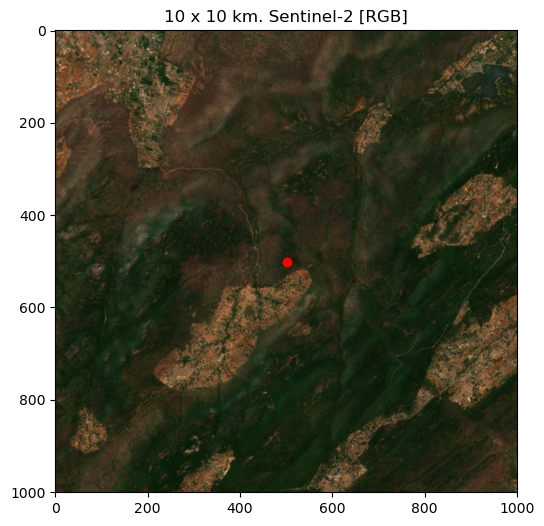

In [32]:
img = cube_sent
img = img.transpose(1,2,0)                     # C x H x W to H x W x C
img = img[:,:,0:3]                             # B,G,R or A0,A1,A2
#img = img[::-1,:,:]                           # reverse the order of rows for alpha earth image
img = img[:,:,::-1]                            # reverse the order bands for sentinel image

print('img min=',img.min())
print('img max=',img.max())

img = img/2500
img = np.minimum(img, 1)
img = np.maximum(img, 0)

base = np.min(img)
img = img-base

plt.figure(figsize=(6,6))
plt.imshow(img)
plt.plot(501,501, 'ro')
plt.title("10 x 10 km. Sentinel-2 [RGB]")
plt.savefig("notebook_plot.jpg", dpi=300, bbox_inches="tight")
plt.show()

## Plot AlphaEarth using matplotlib

In [ ]:
img = cube_alpha
img = img.transpose(1,2,0)                     # C x H x W to H x W x C
img = img[:,:,0:3]                             # B,G,R or A0,A1,A2
img = img[::-1,:,:]                           # reverse the order of rows for alpha earth image
#img = img[:,:,::-1]                            # reverse the order bands for sentinel image

print('img min=',img.min())
print('img max=',img.max())

base = np.min(img)
img = img-base

img = np.minimum(img, 1)
img = np.maximum(img, 0)

plt.figure(figsize=(6,6))
plt.imshow(img)
plt.plot(501,501, 'ro')
plt.title("10 x 10 km image. AlphaEarth [A01,A02,A03]")
plt.savefig("notebook_plot.jpg", dpi=300, bbox_inches="tight")
plt.show()